<a href="https://colab.research.google.com/github/Heris-m/Stock-Monitoring/blob/main/Amita0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

          Nama   Luas Owner
0  Sertipikat1   7827    Ai
1  Sertipikat2  24797    Hd
2  Sertipikat3  24589    Hr
Luas lahan:  57213  m2
Nilai jual: 3432780000 rp


      Nama  Jumlah
0     Kiky    5000
1  Kimhwat    5000
2      Tim    8000
Komisi total:  1029834000


Net jual:  2402946000


[np.float64(2402946.0), np.float64(1029834.0)]
['Net Jual', 'Komisi']


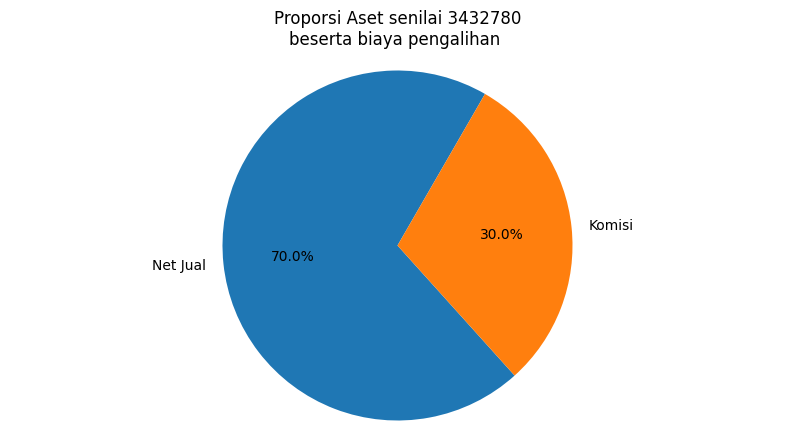

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
#!pip install -U kaleido

harga=60000  # satuan ribu
costSert=7000 # per m2

df_aset=pd.read_csv('/content/drive/MyDrive/Colab Notebooks/dataaset2.tsv', sep='\t')
#print(df_aset.columns)
print(df_aset.head())
lahan_luas=df_aset.Luas.values.sum()
print('Luas lahan: ',lahan_luas,' m2')
aset_jual=lahan_luas* harga
print('Nilai jual:',aset_jual,'rp')
print('\n')

#read komisi
df1=pd.read_csv('/content/drive/MyDrive/Colab Notebooks/datakomisi4b.csv', sep=',') # datakomisi.tsv
print(df1.head())
total_komisi=df1.Jumlah.values.sum() #per m2
jumlah_komisi=total_komisi* lahan_luas #kali luas lahan
print('Komisi total: ',jumlah_komisi)
print('\n')

#read cost document
#df2=pd.read_csv('/content/drive/MyDrive/Colab Notebooks/datacostdoc.csv', sep=',')
#print(df2.head)

#read cost #2 cost sertifikat
costSertif= 50000000  # costSert*lahan_luas
#print('Cost sertipikat: ',costSertif)

#count net_jual
net_jual=aset_jual- jumlah_komisi
print('Net jual: ', net_jual)
print('\n')

#add to list
proporsi_jml=[]
proporsi_jml.append(net_jual/1000)
proporsi_jml.append(jumlah_komisi/1000)
#proporsi_jml.append(costSertif/1000)
print(proporsi_jml)

namaprop=[]
namaprop.append('Net Jual')
namaprop.append('Komisi')
#namaprop.append('Biaya Sertipikat')
print(namaprop)

fig, (ax1) = plt.subplots(1, figsize=(10, 5))
ax1.pie(proporsi_jml, labels=namaprop, autopct='%1.1f%%', startangle=60)
ax1.axis('equal')
ax1.set_title('Proporsi Aset senilai '+str(int(aset_jual/1000))+'\nbeserta biaya pengalihan ')
#food_idx=[]
df_tanah=pd.DataFrame({'NamaProp': namaprop, 'Proporsi': proporsi_jml})

In [ ]:
import numpy as np
import pandas as pd
from openpyxl import Workbook
from openpyxl import load_workbook
from openpyxl.styles import PatternFill
from openpyxl.formatting.rule import CellIsRule
import matplotlib.pyplot as plt
#from datetime import datetime
from datetime import datetime, timedelta
from scipy.signal import find_peaks

def det_pattern(data, smooth_threshold=0.5, min_waves=1):
   data= np.array(data, dtype= float)
   if len(data)<5:
      return('Too few')

   peaks, _= find_peaks(data)
   troughs, _= find_peaks(-data)
   num_waves = min(len(peaks), len(troughs))
#2
   if num_waves>0:
     peak_values= data[peaks[:num_waves]]
     trough_values= data[troughs[:num_waves]]

     amplitudes= peak_values- trough_values
     amp_mean= np.mean(amplitudes)
     amp_std_ratio= np.std(amplitudes)/(amp_mean+ 1e-9)
   else:
     amp_std_ratio= None
#3
   diff=np.diff(data)
   slope_signs= np.sign(diff)
   smoothness= np.std(np.diff(slope_signs))

   if num_waves>min_waves:
      if smoothness<smooth_threshold:
        pattern= 'sinusoidal'
      else:
        pattern= 'triangular'
   else:
      pattern= 'non-osc'
   return(pattern)

# Load the workbook again to apply conditional formatting
wb = load_workbook('/content/drive/MyDrive/Colab Notebooks/stock3z_comby.xlsx')
ws = wb.active

# Define the fill color
green_light_fill = PatternFill(start_color="90EE90", end_color="90EE90", fill_type="solid")
blue_light_fill = PatternFill(start_color="ADD8E6", end_color="ADD8E6", fill_type="solid") # Light blue fill
codes=[] ; OLD= [] ; VD2= [] ; Vuma= [] ; ma5= []
mbar=[] ; doji= [] ; freq= [] ; close= [] ; mstar= []
rejec= [] ; UP2= [] ; BUY= [] ; Lclo= [] ; Sektor= []

# Find the column index for 'close' and 'ma13'
close_col_index = None
up2pct_col_index = None
ma13_col_index = None # Corrected from ma5_col_index to ma13_col_index
ma5_col_index = None
code_col_index = None
Mbar_col_index = None
Doji_col_index= None
buy_col_index= None
freq_col_index= None
oldoji_col_index= None
vuma_col_index= None
vd2_col_index= None
lastc_col_index= None
sektor_col_index= None

Pidx= ws["F1"].value
for col_index, cell in enumerate(ws[2]): # Assuming header is in row 2
    if cell.value == 'close':
        close_col_index = col_index + 1 # openpyxl is 1-indexed
    if cell.value == 'Up2pct':
        up2pct_col_index = col_index + 1
    if cell.value == 'ma20': # Corrected from ma5 to ma13 based on header row
        ma13_col_index = col_index + 1 # openpyxl is 1-indexed

    if cell.value == 'ma5': # Corrected
        ma5_col_index = col_index +1
    if cell.value == 'Code':
        code_col_index = col_index +1
    if cell.value == 'Mbar':
        Mbar_col_index = col_index +1
    if cell.value == 'Doji':
        Doji_col_index = col_index +1
    if cell.value == 'BUY':
        buy_col_index = col_index +1
    if cell.value == 'freq':
        freq_col_index = col_index +1
    if cell.value == 'OLDoji':
        oldoji_col_index = col_index +1
    if cell.value == 'Vd2':
        vd2_col_index = col_index +1
    if cell.value == 'Vuma':
        vuma_col_index = col_index +1
    if cell.value == 'Lastclo':
        lastc_col_index =  col_index +1
    if cell.value == 'Sektor':
        sektor_col_index = col_index +1

if close_col_index is not None and ma13_col_index is not None:    # Apply conditional formatting to the 'ma13' column starting from the third row
    for row_index in range(3, ws.max_row + 1): # Start from row 3 for data
        close_cell = ws.cell(row=row_index, column=close_col_index)
        ma13_cell = ws.cell(row=row_index, column=ma13_col_index) # Corrected to ma13_cell
        ma5_cell = ws.cell(row=row_index, column=ma5_col_index)
        code_cell = ws.cell(row=row_index, column=code_col_index)
        Mbar_cell = ws.cell(row=row_index, column=Mbar_col_index)
        Doji_cell = ws.cell(row=row_index, column=Doji_col_index)
        buy_cell = ws.cell(row=row_index, column=buy_col_index)
        OLDoji_cell = ws.cell(row=row_index, column=oldoji_col_index)
        freq_cell = ws.cell(row=row_index, column=freq_col_index)
        vd2_cell = ws.cell(row=row_index, column=vd2_col_index)
        up2pct_cell = ws.cell(row=row_index, column=up2pct_col_index)
        lastc_cell = ws.cell(row=row_index, column=lastc_col_index)
        sektor_cell = ws.cell(row=row_index, column=sektor_col_index)

  # pre condition for lastclo
        if (lastc_cell.value is not None and lastc_cell.value>7): #or code_cell.value in parr:
           codes.append(code_cell.value)
           close.append(close_cell.value)
           ma5.append(ma5_cell.value)
           mbar.append(Mbar_cell.value)
           doji.append(Doji_cell.value)
           OLD.append(OLDoji_cell.value)
           BUY.append(buy_cell.value)
           freq.append(freq_cell.value)
           VD2.append(vd2_cell.value)
           UP2.append(up2pct_cell.value)
           Lclo.append(lastc_cell.value)
           Sektor.append(sektor_cell.value)
    print(codes)
    print(len(codes))
    print(len(mbar))
    print(len(Sektor))
df_codes= pd.DataFrame({'Code':codes, 'Mbar':mbar, 'ma5':ma5, 'close':close, 'Lastclo':Lclo, 'Doji':doji, 'OLDoji':OLD, 'BUY':BUY, 'Vd2':VD2, 'Freq':freq, 'Up2%':UP2 ,'Sektor':Sektor})
report_df = df_codes[['Code', 'Mbar', 'ma5', 'close', 'Lastclo', 'Doji', 'OLDoji', 'BUY', 'Vd2', 'Freq', 'Up2%','Sektor']]

pidx_df = pd.DataFrame({'Date': [Pidx]})  # ' close>ma20

# Concatenate the Pidx DataFrame with the report_df
report_df = pd.concat([pidx_df, report_df], ignore_index=True)
# Write the DataFrame to an Excel file
output_filename = '/content/drive/MyDrive/Colab Notebooks/stock_hilast.xlsx'
report_df.to_excel(output_filename, index=False, startrow=0) # Startrow 0 to include the Pidx row
# Save the workbook

# Load the workbook again to apply conditional formatting
wb = load_workbook('/content/drive/MyDrive/Colab Notebooks/stock_hilast.xlsx')
ws = wb.active

for col_index, cell in enumerate(ws[1]): # Assuming header is in row 1
    if cell.value == 'ma5':
        ma5_col_index = col_index +1
    if cell.value == 'Freq':
        freq_col_index = col_index +1

# Apply conditional formatting if columns are found
if freq_col_index is not None:      # Added c#heck for ma13_col_index
   for row_index in range(3, ws.max_row + 1): # Start from row 3 for data
        freq_cell = ws.cell(row=row_index, column=freq_col_index)  # Apply conditional formattin#
        if (freq_cell.value is not None and isinstance(freq_cell.value, (int, float)) and
           freq_cell.value < 2000):
            freq_cell.fill = blue_light_fill
# Save the modified workbook
wb.save('/content/drive/MyDrive/Colab Notebooks/stock_hilast2.xlsx')

['ASPI', 'ATAP', 'BAJA', 'BLUE', 'CBRE', 'CTTH', 'FUJI', 'GOLD', 'GTSI', 'IDEA', 'INTA', 'MANG', 'MORA', 'MTPS', 'NAYZ', 'PADA', 'PBSA', 'PGLI', 'PSAB', 'RSCH', 'SCNP', 'SGER', 'SOSS', 'TNCA', 'UANG', 'VINS']
26
26
26


In [ ]:
import pandas as pd
import numpy as np
from openpyxl import Workbook
from openpyxl import load_workbook
from openpyxl.styles import PatternFill
from openpyxl.formatting.rule import CellIsRule
import matplotlib.pyplot as plt
import plotly.express as px
from datetime import datetime, timedelta
import os

def cekOpnRcg(oparr, lclo):
# cek res opn vs clo3
   ropn= len(oparr)     # opn Rcgv
   les= 0
   for i in range(ropn):
#      if dayMbx>-1:
#        if dayRcg[i] < dayMbx: # important 12 - 11 TAYS
#          if oparr[i]>lclo:
#            les+=1
#      else:
       if oparr[i]>lclo:
          les+=1
   return les

def codeStock0(df, bwh):
   df['Hiclo'] = round(((df['High'] - df['Prev']) * 100) / df['Prev'], 2)
   df['Loclo'] = round(((df['Low'] - df['Prev']) * 100) / df['Prev'], 2)
   df['Cloclo'] = round(((df['Close'] - df['Prev']) * 100) / df['Prev'], 2)
   df['Opclo']=df.apply(lambda row: 1 if row['Open']>row['Prev'] else 0, axis=1)
   df['DOJI']=df.apply(lambda row: 1 if row['Open']==row['Close'] else 0, axis=1)# Filter rows where the length of the 'Code' column is 4
   df['OL1']=df.apply(lambda row: 1 if (row['Open']==row['Low']) and (row['Close']>row['Open']) else 0, axis=1)
   df['DOJI2']=df.apply(lambda row: 1 if row['Open']<row['Close'] else 0, axis=1)
  # df['Mid']= round((df['Open'] +df['Close'])/2, 1)
   Req1= df['Code'].str.len() == 4
   Req2x=df['Close']<1100
   return(df[Req1 & Req2x])

def daycont(str1, str3):
   d1= datetime.strptime(str1, '%d-%b-%Y')
   d3= datetime.strptime(str3, '%d-%b-%Y')  #   weekdays=pd.bdate_range(start=str1, end=str3)
   cont=0
   i= d1
   while i<= d3:
     if i.weekday() < 5:
       cont+=1
     i+=timedelta(days=1)  #  delta= d3 - d1
   # cek cuti
   d2= datetime.strptime('16-Jan-2026', '%d-%b-%Y')
   d3= datetime.strptime('16-Feb-2026', '%d-%b-%Y')
   d3b= datetime.strptime('17-Feb-2026', '%d-%b-%Y')
   d4= datetime.strptime('18-Mar-2026', '%d-%b-%Y')
   d4b= datetime.strptime('19-Mar-2026', '%d-%b-%Y')
   d5= datetime.strptime('20-Mar-2026', '%d-%b-%Y')
   d5b= datetime.strptime('23-Mar-2026', '%d-%b-%Y')
   d5c= datetime.strptime('24-Mar-2026', '%d-%b-%Y')
   d6= datetime.strptime('03-Apr-2026', '%d-%b-%Y')

   if d1<d2:
      cont-= 9 # 8 3 1
   else:
      if d1> d2 and d1< d3:
         cont-= 8 # 7 2
      elif d1> d3b and d1< d4:
         cont-= 6 # 5
      elif d1> d5c and d1< d6:
         cont-= 1   #
   return(cont)  # daycont(dtMh3, currStr)

datfile=['SCR_20260212', 'SCR_20260213', 'SCR_20260218',
         'SCR_20260219', 'SCR_20260220', 'SCR_20260223', 'SCR_20260224', 'SCR_20260225', 'SCR_20260226',
         'SCR_20260227', 'SCR_20260302', 'SCR_20260303', 'SCR_20260304', 'SCR_20260305', 'SCR_20260306',
         'SCR_20260309', 'SCR_20260310', 'SCR_20260311', 'SCR_20260312', 'SCR_20260313', 'SCR_20260316',
         'SCR_20260317', 'SCR_20260325', 'SCR_20260326', 'SCR_20260327', 'SCR_20260330', 'SCR_20260331',
         'SCR_20260401', 'SCR_20260402', 'SCR_20260406', 'SCR_20260407', 'SCR_20260408', 'SCR_20260409',
         'SCR_20260410', 'SCR_20260413', 'SCR_20260414', 'SCR_20260415', 'SCR_20260416', 'SCR_20260417',
         'SCR_20260420', 'SCR_20260421', 'SCR_20260422', 'SCR_20260423', 'SCR_20260424', 'SCR_20260427',
         'SCR_20260428', 'SCR_20260429', 'SCR_20260430']

exl= 46 #+ 4  # 38 '27-Jan-2026' 39+5+2
currStr= '30-Apr-2026'

hi13grp= [0] * 13
Sektot_clo= [0] * 12
Sektot_clo1= [0] * 12
SektCode_num= [0] * 12

dFil=len(datfile)    #df_cont = dFil
print('dFil = ', dFil)
df_cont = dFil
dfarr=[pd.DataFrame() for _ in range(df_cont)]

for i in range(dFil):        #   ScrFil=bulan72+str(i+1)+'.csv'  # tgl 21 - 25
   ScrFil=datfile[i]+'.csv'
#   print(ScrFil)
   df1=pd.read_csv('/content/drive/MyDrive/Colab Notebooks/'+ScrFil, sep=",") #df1a=df1.drop(['No', 'Time'], axis=1)
   dfarr[i]=codeStock0(df1, 2)

dfxbow=[None] * len(dfarr)
hix=[None] * len(dfarr)
hi=[None] * len(dfarr)
lox=[None] * len(dfarr)
lo=[None] * len(dfarr)
cloclo=[None] * len(dfarr)
clo=[None] * len(dfarr)
opn=[None] * len(dfarr)
mid=[None] * len(dfarr)
OLx=[None] * len(dfarr)
OCx=[None] * len(dfarr)
djx=[None] * len(dfarr)
djy=[None] * len(dfarr)
vol=[None] * len(dfarr)
value=[None] * len(dfarr)
freq=[0] * len(dfarr)
tgl=[None] * len(dfarr)
avg= [None] * len(dfarr)
lenarr=len(dfarr)

yarr=['ACRO','BKSL','CITY', 'AGRS','BVIC', 'JAST','AHAP', 'JKON', 'MDLN', 'ADCP',
      'BAPA', 'BSBK', 'BCIP','LPKR', 'TAYS', 'LUCK', 'MPIX', 'BRRC', 'OKAS', 'PTMP',
      'DNAR','TMPO','HDIT','MLPL','BABP','GEMA', 'KUAS', 'BCAP', 'WEGE', 'NASI',
      'MEDS', 'MPOW', 'GRIA', 'JAWA', 'SMBR', 'SURI', 'CHEM', 'JATI', 'HALO', 'DIVA',
      'VTNY', 'KBLV', 'SICO', 'NPGF', 'DILD', 'BUMI', 'COAL', 'MAXI', 'IOTF']
#'DKHH',
#      'LAJU','LABA', 'LPKR', 'MPOW', 'KAQI', 'OKAS', 'NASI', 'PTMP', 'CHEM', 'WEHA']
#      'TAYS', 'VTNY','SRSN','TOOL', 'GSMF', 'KPIG', 'PAMG', 'JMAS', 'JAYA', 'GRPH',
#      'OPMS', 'WEGE', 'PRIM', 'MEDS', 'TRJA', 'SWID', 'TOSK', 'JATI', 'SMGA',
#      'MDLN', 'SLIS', 'WOWS', 'RUIS', 'SICO','BGTG', 'MHKI', 'VKTR', 'PSDN',
#      'SDMU', 'KBLV', 'ASLC']
#      'UNTD', 'VISI', 'VTNY','IOTF']

codes_comby=sorted(list(yarr)) # yarr
print(codes_comby)
print(lenarr)
#dfarr[40]['Date'].iloc[0]
Sektor_uniq= []; dfrow= None

# read code sektor into list
df1a=pd.read_csv('/content/drive/MyDrive/Colab Notebooks/list_sektor3h.csv')
# Replace 'PERINDUSTRIAN' with 'INDUSTRI' in the 'SEKTOR' column
df1a['SEKTOR'] = df1a['SEKTOR'].replace('PERINDUSTRIAN', 'INDUSTRI')
df1a['SEKTOR'] = df1a['SEKTOR'].replace('Brg konsumen bukan primer', 'Brg Konsumen bukan primer')

print(df1a.columns)
saham=df1a['SAHAM'].values
Sektor=df1a['SEKTOR'].values # SUBSEKTOR

# --- Sektor get indexed by code saham
codeSect={}
for i,elm in enumerate(saham):
   if pd.notna(elm):
     codeSect[elm]=Sektor[i]
   else:
     print(elm)

# cek code sektor dari codes_comby
codeSect_ketr={}
non= 0
for i,elm in enumerate(codes_comby):
   if elm not in codeSect:
#     code_noList.append(elm)
      codeSect[elm]='none'
      codeSect_ketr[elm]='none'
      non= 1
   else:
      codeSect_ketr[elm]=codeSect[elm]
     # add into Sektor uniq
      if codeSect[elm] not in Sektor_uniq:
         Sektor_uniq.append(codeSect[elm])

# Cek non existent sector or none
if non== 1:
   Sektor_uniq.append('none')

print(len(codeSect_ketr),' ',codeSect_ketr)

Sektor2_uniq= sorted(Sektor_uniq)
print('Sektor2 uniq/ len: ', Sektor2_uniq, ' ', len(Sektor2_uniq))

# -----------------
# Read Sinyal1.csv
dfx= [pd.DataFrame() for _ in range(6)]
#string_var= ''
csvGrp= ['Sinyal1.csv','Sinyal2.csv','Sinyal3.csv', 'Sinyal4.csv', 'Sinyal5.csv', 'Sinyal6.csv']
numGrp= len(csvGrp)

for i in range(numGrp):
    csv_file0= csvGrp[i]  # 'Sinyal'+str(i+1)+'.csv'  #csv_file0= 'Sinyal1.csv'
    csv_file1= '/content/drive/MyDrive/MyDocs/Colab/'+csv_file0
    print(i,' ',csv_file1)
    dfx[i]= pd.read_csv(csv_file1)

  # cleaning the space char
    dfx[i]['Code']= dfx[i]['Code'].str.lstrip()
#    if i==2:
#    string_var= dfx[i]['Code'].values
#    print(string_var, ' -', len(string_var))

# Join dfx base on noGrp
df_Tot= pd.concat([dfx[0], dfx[1], dfx[2], dfx[3], dfx[4], dfx[5]])

#df2= pd.read_csv(csv_file1)
codeSign= df_Tot['Code'].values # dfx[0] df2
macdSign= df_Tot['MACD'].values
stochSign= df_Tot['Stoch'].values #bbandSign= df_Tot['BBand'].values
PERSign= df_Tot['PER'].values
PBVSign= df_Tot['PBV'].values
ROESign= df_Tot['ROE'].values

codeSg_macd= {}; codeSg_stoch= {}; codeSg_PBV= {}
codeSg_PER= {}; codeSg_ROE= {}
for i, elm in enumerate(codeSign):
    codeSg_macd[elm]= macdSign[i]
    codeSg_stoch[elm]= stochSign[i] #   codeSg_bband[elm]= bbandSign[i]
    codeSg_PER[elm]= PERSign[i]; codeSg_PBV[elm]= PBVSign[i]
    codeSg_ROE[elm]= ROESign[i] #    print(codeSg_macd[elm])

# ---- Integrate to codes_comby -----
codeMacd_ket= {}; codeROE_ket= {}
codeBband_ket= {}; codePER_ket= {}; codePBV_ket= {}
for i, elm in enumerate(codes_comby):
   if elm not in codeSign: # codeSg_macd
      codeMacd_ket[elm]= '-' #     codeBband_ket[elm]= '-'
      codePER_ket[elm]= '-'; codeROE_ket[elm]='-'
#      codePBV_ket[elm]= '-'
   else:
      codeMacd_ket[elm]= codeSg_macd[elm]+ ' '+ codeSg_stoch[elm] # codeBband_ket[elm]= codeSg_bband[elm]
      codePER_ket[elm]= codeSg_PER[elm]
 #     codePBV_ket[elm]= codeSg_PBV[elm]
      codeROE_ket[elm]= codeSg_ROE[elm]
print(codeMacd_ket)
#print(codeBband_ket)

# Create a new workbook and select the active sheet
wb = Workbook()
ws = wb.active
ws.title = "Stock Report"

# write the header for date
row_date=['Date']
for i in range(lenarr):
   if i>exl:    # excel print
     row_date.append(dfarr[i]['Date'].iloc[0])
     row_date.append('')
print(row_date)
ws.append(row_date)

# Write the header row for codes
codes_header=['Code']
for i in range(lenarr):
   if i>exl:   # add excel print 1 -> tgl 4
     codes_header.append('Hiclo')
     codes_header.append('Loclo')
#codes_header.append('Lastclo')
codes_header.append('close')
codes_header.append('ma5') #codes_header.append('ma20')
codes_header.append('Doji5')
#codes_header.append('OL1')
codes_header.append('Buy')
codes_header.append('Vd2-Vuma') #codes_header.append('VUma5')#codes_header.append('VMA20r')
codes_header.append('Hiav13') #codes_header.append('Rejval5') #codes_header.append('Mstar')
codes_header.append('Freq')
codes_header.append('Bar2up') #codes_header.append('VMA20s')
codes_header.append('RcgDn') # Spikes5#codes_header.append('Bma32')
#codes_header.append('Vspike20')   # Vspike2Odown30
codes_header.append('code2')
codes_header.append('MacStoc') #codes_header.append('BolBand')
codes_header.append('PER')
codes_header.append('Avg')
codes_header.append('ROE')
ws.append(codes_header)

# read last value then rank
Valcode= []
#for code in codes_comby:   # Get data from df1b for the current code
   # Check if dfarr[45] contains the current code
#   temp_df_filtered = dfarr[45][dfarr[45]['Code'] == code]
#   if not temp_df_filtered.empty:
#       value3 = temp_df_filtered['Value'].iloc[0]
#       Valcode.append(round(value3/1000000))
#   else:       # If the code is not found in dfarr[45], append a default value, e.g., 0       # This prevents IndexError if a code from codes_comby is not present in this specific daily dataframe.
#       Valcode.append(0)
#print(Valcode)

# Clcode3= {};
Bma32_tr={}; Bears= {} # Corrected from Bma32_tr={}.
DtrenC= {} # Bma21_tr={};
MAmid={}
Lstar= {}; tulis= 1; Doj3= {}; ODclohi= {}
Sekt_smry= []; Code_smry= []; Clc_smry= []
for code in codes_comby:
    row_data = [code]
    dojval= spike= OLdval= 0 #dayRej1= -1
    dtStl3= ''; daySp3= dayG3= -1;
    vlosgrp=[] ; daySp83= dayRej3= -1
    clo2grp= []; OL1m1= OL1m2= OL10= OL11= OL13= 0
    ODm2= ODm1= OD0= OD1= OD3= 0
    dojm2= dojm1= doj0= doj1= doj3= 0
    clc21= clc23= clc1= clc20= 0   # vrcg1= vrcg3= 0;  #clcm1= clcm3= 0
    clom1= clom2= 0; dn30_cont= 0; iBuy= 0
    volm2= volm1= vol0= vol1= vol3= 0
    mid5grp=[]; dn30dis= [] #i2= lenarr-32-1
#
    opn0= opn1= opn3= 0 ; hi0= hi1= hi3= ihi= hival= 0
    clo0= clo1= clo3= 0 ; rejval= opBar2= 0
    value3= 0; OC11= OC13= 0 ; Vmas= 0
    dtBr3= dtSp83= ''; freq3= 0; dayBr3= -1
    dtVol3= ''; dayVol3= -1  # = dayBc4= -1
    mvol53= mvol103= mvol203= dma520= 0
    clc23c= 0; dayBma= -1; dtRej3= ''

    # Initialize clc23a, clc23b, clo3a, clo3b with default values
    clc23a= 0; dtMb3= ''; dayMb3= -1; #= dayRej0= -1
    clc23b= 0; dayMbs= 0; val2m= 0; kRex= -1
    dn30_tot= RcgDn= 0;
    dayRex= dayRey= sRex= -1
    clo3a = clo3b= minclo= minopn= ix= 0
    tma10val= tma20val= ma10val= ma20val= 0
    Sumid5= []; clogrp= []  # clogrp= []
    Vupval= 0; Vd2val= 0; vspike= 0
    hires= divAbs= 0; ma5val= 0; dtBma32= ''
    i20= lenarr-36-1; dayGx= []; opnGx= []
    ClcSum= 0 ; cloGx= []; daySp8x= []
    volast= 0; lowGx= []; dayBma32= -1
    cRex= []; lenGx= 0; avg3= 0
    Bma32_tr[code]= -1; dtMh3= ''; Res= 0
    dayMh3= -1; opnMhx= []; dayMhx= [] #volMhx= [];
    iy= 0; dayMbx= []; cloSp8=[] # minlox

    for i,df in enumerate(dfarr): # Corrected variable name here
       # Get data from df1b for the current code
       dfxbow[i]= df[df['Code'] == code]
       if not dfxbow[i].empty:
          hix[i] = dfxbow[i]['Hiclo'].iloc[0]  # hiclo1
          hi[i] = dfxbow[i]['High'].iloc[0]
          lox[i] = dfxbow[i]['Loclo'].iloc[0]
          lo[i] = dfxbow[i]['Low'].iloc[0]
          cloclo[i] = dfxbow[i]['Cloclo'].iloc[0]
          clo[i] = dfxbow[i]['Close'].iloc[0]
          opn[i] = dfxbow[i]['Open'].iloc[0]
          OLx[i] = dfxbow[i]['OL1'].iloc[0]
          OCx[i] = dfxbow[i]['Opclo'].iloc[0]
          djx[i] = dfxbow[i]['DOJI'].iloc[0]
          djy[i] = dfxbow[i]['DOJI2'].iloc[0]
          vol[i] = dfxbow[i]['Volume'].iloc[0]
          value[i] = dfxbow[i]['Value'].iloc[0]
          freq[i] = dfxbow[i]['Freq'].iloc[0]#          mid[i] = dfxbow[i]['Mid'].iloc[0]
          tgl[i] = dfxbow[i]['Date'].iloc[0]
          avg[i] = dfxbow[i]['Avg'].iloc[0]

          if i>exl:   # excel print
            row_data.extend([hix[i], lox[i]])

          if hix[i]>3 and hix[i]<8: # cek spike
             dtSp3= tgl[i]
             daySp3= daycont(dtSp3, currStr) -1
             if daySp3< 15:  # 22
                daySp8x.append(daySp3)
                spike+=1
          else:
             if hix[i]>=8:
                dtSp83= tgl[i]
                daySp83= daycont(dtSp83, currStr) -1
                if daySp83< 15:
                   cloSp8.append(clo[i])
                   daySp8x.append(daySp83)
                   spike+=1

     #     clcm3= clcm2; clcm2= clcm1; clcm1= clc0
          clc0= clc1; clc1= clo3; clo3= clo[i]

        # read close 3 close
          clc20= clc21; clc21= clc23; clc23= cloclo[i]
        #  Clcode3[code]= clc23  #  Clcode1[code]= clc21

          if i>i20:      # cek for the last 20
             mid5grp.append(clc23)

          if (clc23> 7.9) and clo[i]>opn[i]: # 6.9
             dtMb3= tgl[i]
             dayMb3= daycont(dtMb3, currStr)- 1
             dayMbx.append(dayMb3)
        #     pass
          else:
             if clo[i]< opn[i] and (clc23< -3.0 or lox[i]<-2.5): # lox<-3.0
                if vol[i]> vol3 and vol3> 0:
                   dtMh3= tgl[i]
                   dayMh1= dayMh3
                   dayMh3= daycont(dtMh3, currStr) -1
                   if dayMh3< 31:
                      opnMhx.append(opn[i])
                      dayMhx.append(dayMh3)        #              volMhx.append(vol[i])

          if (lox[i]<-3.0): # and (clc23<0):  # -2.0
 #             if opn[i]>clo[i]:     #and vol[i]<vol3:
                 dtStl3= tgl[i]
                 dayG3= daycont(dtStl3, currStr) -1
                 if dayG3< 22:
                    rejval+=1
                    cloGx.append(clo[i]); opnGx.append(opn[i])
                    lowGx.append(lo[i])
                    dayGx.append(dayG3)
         # Bearish
          if opn3< clc1 and opn3> clo[i] and opn[i]>= clc1:  # clc1<=opn[i]
                 dtBr3= tgl[i]
                 dayBr3= daycont(dtBr3, currStr) -1

        #         if code=='BVIC':
        #             print(i,' ', clc23, ' dayBr3 opn3 clc1 opni cloi : ',  dayBr3,'/',opn3, ' ',clc1,'- ',opn[i], ' ',clo[i]) #,' -',opn1,' ',clc0)
        #  elif  clc1>= opn[i] and opn[i]>= clo[i] and opn3> clc1:
        #         dtBc3= tgl[i]
        #         if clo[i]> lo[i]: #  ada ekor
        #            dayBc3= daycont(dtBc3, currStr) -1
        #         else:
       #             dayBc4= daycont(dtBc3, currStr) -1
         # read value
          value3= round(value[i]/1000000)
          freq3= freq[i]         # opn1= opn3; opn3= opn[i
          if value3> 2000:
             val2m+= 1
         # keep last OL
          OL1m2= OL1m1; OL1m1= OL10; OL10= OL11
          OL11= OL13; OL13=OLx[i]
          ODm2= ODm1; ODm1= OD0; OD0= OD1
          OD1= OD3; OD3= djy[i]

        # keep last doji
          dojm2= dojm1; dojm1= doj0
          doj0= doj1; doj1= doj3; doj3= djx[i]
         # keep volume
          volm2= volm1; volm1= vol0
          vol0=vol1 ; vol1=vol3 ; vol3=vol[i]
          if vol3< vol1 and vol1< vol0 and vol0< volm1:
             if volm1> 3* volm2:
                dtVol3= tgl[i]
                dayVol3= daycont(dtVol3, currStr)- 1
         # keep opn
          opn0=opn1; opn1=opn3; opn3= opn[i]
    #      clc0= clc1; clc1= clc23
         # keep hi & Opclo
  #        hi1= hi3; hi3= hi[i]
          OC11= OC13; OC13= OCx[i]
          avg3= avg[i]

         # add volume and close into list
          vlosgrp.append(vol[i])
          if len(vlosgrp)>=20:
             vol53g= vlosgrp[-5:] # take the last 5 volume
#             mvol51= mvol53
             mvol53= sum(vol53g)/len(vol53g)
         #   ma10
             vol103g= vlosgrp[-10:]  #   mvol101= mvol103
             mvol103= sum(vol103g)/len(vol103g)
         #   ma20
             vol203g= vlosgrp[-20:]  #   mvol201= mvol203
             mvol203= sum(vol203g)/len(vol203g)
         #   VMA ratio
         #    Vmar0= Vmar1; Vmar1= Vmar3
         #    if mvol53>0:
         #       Vmar3= round(mvol53/mvol203, 1)
         #   vspike tvol over mvol20
         #    if vol[i]> mvol203:
         #       dtVsp3= tgl[i]
          #      dayVsp3= daycont(dtVsp3, currStr)
         #       if dayVsp3<10:
        #           vspike+=1

         #   collect for MA
          clo2grp.append(clo[i])
          if len(clo2grp)>=20:
         #   ma20
             ma20g= clo2grp[-20:]
             tma20val= sum(ma20g)/len(ma20g)
         #   ma5
             ma5g= clo2grp[-5:]
             tma5val= round(sum(ma5g)/len(ma5g), 1)
         #   ma10
             ma10g= clo2grp[-10:]
             tma10val= round(sum(ma10g)/len(ma10g), 1)

         # Collect freq #        flosgrp.append(freq[i])
          dataclo={'close': clo2grp}
  #        dfc= pd.DataFrame(dataclo)
          if len(clo2grp)>=26:
         #   Ema9
         #    dfc= pd.DataFrame(dataclo)
         #    dfc['EMA26']= dfc['close'].ewm(span= 26, adjust= False).mean()
         #   find Delta ma5 ma20
             if clo3<=tma5val and clo3>tma20val:
                dma520= tma5val- tma20val
                if dma520< 5:
                   dtBma= tgl[i]
                   dayBma=daycont(dtBma, currStr) -1

         #   reject 2 under
         #   ma30
          if len(clo2grp)>=30:
             ma30g= clo2grp[-30:]
             tma30val= sum(ma30g)/len(ma30g)
            #
             dn30_tot+= 1
             if tma30val>clo3:
                dn30_cont+=1
           #     dn30dis.append(1) # last 18 data
           #  else:
           #     dn30dis.append(0)

#             dma1020= tma10val- tma5val
           #  if tma5val< tma10val:
           #     dma1020= tma10val- tma5val
           #     if dma1020> 0.01:
           #        Bma21_tr[code]= 1
           #     else:
           #        Bma21_tr[code]= 0
           #  else:     # tma20 < tma10
           #     Bma21_tr[code]= 0

         # hi13 circular
          hi0= hi1; hi1= hi3; hi3=hix[i]
          if hi3>0:
             hi13grp[ihi]= hi3   # higrp.append(hi3)
          else:
             hi13grp[ihi]= 0     # higrp.append(0)

          if ihi>=12:
            ihi= 0
          else:
            ihi+=1

       #   if code=='BSBK':
       #      print(i,'- ',clc1, ' ', opn1, ' ',clo[i], ' ', opn[i],'/ ', clc21, ' ',clc23)
        # cek Bar2up
          if clc1> opn1 and clc21< 3.5 and clo[i]> opn[i]:
             if 3< clc23<= 12:
                dtRej3= tgl[i]   # dayMh3,'/',dtMh3,' ',opn[i], ' ',clo[i],'- ',round(vol3/100),' ', round(vol1/100), ' ',dma1020) # ,tma5val,' ',tma20val, ' '
                dayRej3= daycont(dtRej3, currStr)- 1
                opBar2= opn1     #   opn3      if code=='SURI':
        # cek 2nd
          if dayRej3==-1:
             if clc1> opn1 and 3< clc21<= 12 and clo[i]> opn[i]:
                if clc23< 3.5:
                   dtRej3= tgl[i]
                   dayRej3= daycont(dtRej3, currStr)- 1
                   opBar2= opn1
       else:
         # print
          if i>exl:  # excel print
            row_data.extend(['', ''])
# Get last data
# Exit date loop
    for k, elm in enumerate(Sektor2_uniq): # Sektor2_uniq[0]
       if codeSect_ketr[code]== elm:
          if clc23 != '':
             Sektot_clo[k]+= clc23 # save jumlah clc codes yg sama sektor
          else:
             Sektot_clo[k]+= 0
        # Get prev data clc21 & are added
       #   Sektot_clo1[k]+= clc21

          SektCode_num[k]+= 1   # jumlah code per sektor
          Code_smry.append(code)
          Sekt_smry.append(elm)
#          Clcode3[code]= clc23
          Clc_smry.append(clc23)

#          if k==0:          # SektCode_num[0]+= 1
#             print('code0: ', code)
#          if k==1:
#             print('code1: ', code)
#          if k==2:
#             print('code2: ', code)

 # create df vol column
    dataclo= {'volume': vlosgrp}
    dfc= pd.DataFrame(dataclo)
    dataclo2= {'close': clo2grp} # ma5
    dfc2= pd.DataFrame(dataclo2)
#    dataflo3= {'frequency': flosgrp}
#    dfc3= pd.DataFrame(dataflo3)
#    dfc2['EMA26']= dfc2['close'].ewm(span= 26, adjust= False).mean() # Check if DataFrames are empty before accessing elements
#    dfc2['EMA9']= dfc2['close'].ewm(span= 9, adjust= False).mean()

    if not dfc.empty:
        dfc['VMA5']=dfc['volume'].rolling(window=5).mean()
        vol53= dfc['VMA5'].iloc[-1]
        dfc['VMA10']=dfc['volume'].rolling(window=10).mean()
        vol103= dfc['VMA10'].iloc[-1]
        dfc['VMA20']=dfc['volume'].rolling(window=20).mean()
        vol203= dfc['VMA20'].iloc[-1]
    #  cek volma20
        volast= round(vol3/vol203, 1)  # dfc['volume'].iloc[-1]
    else:
        vol53 = vol103 = vol203 = 0

    if not dfc2.empty:
        dfc2['SMA5']=dfc2['close'].rolling(window=5).mean()
        ma5val= dfc2['SMA5'].iloc[-1]
        dfc2['SMA10']=dfc2['close'].rolling(window=10).mean()
        ma10val= dfc2['SMA10'].iloc[-1]
        dfc2['SMA20']=dfc2['close'].rolling(window=20).mean()
        ma20val= dfc2['SMA20'].iloc[-1]
    else:
        ma5val = ma10val = ma20val = 0

   # ma20val= round(tmac20val)
# doji cont
    dojgrp=[dojm2,dojm1,doj0,doj1, doj3]  #
    dojgrp=np.array(dojgrp)
    dojval = dojgrp.sum()
# Cek doji & OD clo hi
    Doj3[code]= doj3+ doj1
    if hi3> 8.0 and OD3> 0:
       ODclohi[code]= 1
    else:
       ODclohi[code]= 0
# OD green doji2
    ODgrp=[ODm1, ODm2, OD0, OD1, OD3]
    ODgrp=np.array(ODgrp)
    ODval= ODgrp.sum()
 # OL1
    OLgrp=[OL1m2, OL1m1, OL10, OL11, OL13]
    OLgrp=np.array(OLgrp)
    OLval= OLgrp.sum()
# OLd
# higrp
    hi13grp=np.array(hi13grp)
    hi13val = round(hi13grp.mean(), 1)
  # hival
    higrp= [hi0, hi1, hi3]
    higrp= np.array(higrp)
    hi3val= round(higrp.mean(), 1)
  # MAmid between: ma5< clo3< ma20
  #  if hi3val>= hi13val:
  #     MAmid[code]= 1
  #  else:
  #     MAmid[code]= 0
  # opn RCGV
    if dn30_cont>= 2:
       Res= cekOpnRcg(opnMhx, clo3)
       if Res>0:
          DtrenC[code] = 1
       else:
          DtrenC[code] = 0
    else:
       DtrenC[code] = 0
  # dist dn30

  # clo3 over last 36 days #32
 #   clogrp=clo2grp[-36:] # verified
#    if clogrp: # Add check for empty list
#    Sumid5= np.array(mid5grp)
#    ClcSum= Sumid5.sum()
# Get opnMhx max
    if opnMhx:
       opnmax= np.max(opnMhx)
       iy= opnMhx.index(opnmax)
       RcgDn= round((clo3- opnmax)*100/opnmax, 2) #round(vol3/freq3)
    else:
       RcgDn= 0

    if dayMbx and daySp8x:     # keep dayMb3
       dayMb3= dayMbx[-1]
       if dayMb3< daySp8x[-1]: #   if dayMb3< 5:
          dayMbs= 3
       else:
          dayMbs= 0

  # last clo
    clostr= []; movd= []; val= []; movd2= []
    Buys= []; Lclo= []; Vuml= []; Spk= []
    Spk8= []; Freq= []; VMA= []; OLd= []
    Vup= []; Vd= []; Doji= []
    VMA3= []; VMA1= []; Sect= []; Hiav= []
    Hiav3= []; BMA= []; VMA20= []; Rej= []
    BMA32= []; Dn30= []
#    arrclo= []  #    arrclo.append(clo0); arrclo.append(clo1)
#   determine index dayGx rejec in 22 days#    minlox= min(loGx)
    sRex= 0; lenGx= len(lowGx)
    if lowGx:
       ix= lowGx.index(min(lowGx))
       minclo= cloGx[ix]
       minopn= opnGx[ix]
     #  clc23a= round((min(lowGx) - minclo) *100/minclo, 2)
     #  if clc23a<-2.9: # baru dianggap reject

       dayRex= dayGx[ix]
       #  if minclo< minopn:
       #  cont beda for Rej panjang
       clc23c= minopn- minclo
       clc23b= minopn- min(lowGx)
       if clc23c!= 0:
          kRex= abs(round(clc23b/ clc23c, 1))
       else:
          kRex= 0        #  if clc23b>= 2*clc23c:

       sRex= 0
     # cek all lowGx list for kRex
       for i in range(lenGx):
           minclo= cloGx[i];  minopn= opnGx[i]
           clc23c= minopn- minclo
           clc23b= minopn- lowGx[i]
           if clc23c!= 0:
              kRex= abs(round(clc23b/ clc23c, 1))
              cRex.append(kRex)
           else:
              cRex.append(0); kRex= 0
         # find the greatest kRex and idx
           if kRex> sRex:
              sRex= kRex; iy= i
           #   dayRey= dayGx[

  # cek the result
    if code=='JAWA':  #       print('code tma1020: ', code, '/ ',ma20val,' ',ma10val)
       print('\n')
#       print('ma5val ma10val ma20val dayRex : ',ma5val, ' ', tma10val, ' ', tma20val, '/', dayRex) # rejval
#       print('clo rej: ', clo0, ' ', clo1, ' ', clor3)
       print(code,' dayBar2up RcgDn opBar2: ', dayRej3, ' ',RcgDn,' ',opBar2,'/',ix) #' ', dayMhx)
       print(code,' minlox minclo minopn: ', min(lowGx) ,' ',minclo, ' ', minopn,' ') # opnMhx
       print(code,' clc23c dayRex dayVol3: ', ' ',clc23c,' ',dayRex, ' ', dayVol3) # len(lowGx))  # dojval
       print(code,' sRex iy dayGx: ', sRex, ' ',iy, ' ', dayGx[iy])
#       print(code,' cRex: ', cRex)
#       print(code,' opnGx: ', opnGx

#       if cloSp8:
#          print('cloSp8 : ', cloSp8)
#          print('daySp8x : ', daySp8x)
 #   print ('\n')
  # Vupval signal
    if vol3> 2* vol1:
       Vupval= 1
      # Cek Divergence Absorp #       if OD3> 0 and OD1> 0:  #  hi0= round((hi3+ clc23)/2, 1)
       if clc21> 1.05* clc23: # and OD1> 0 and clo3>= opn3:
          divAbs= 1
          Bma32_tr[code]= 1
       else:
          Bma32_tr[code]= 0
    else:
       Vupval= 0
       Bma32_tr[code]= 0

  # Vol down stat
    if vol3<vol1:
       if vol1<vol0:
          Vd2val = 2
  # cek volt dn5
          if vol0< volm1:
             if volm1>3* volm2:
                Vd2val= 5
       else:
          if vol3<vol0:
             Vd2val= 1
          else:
             Vd2val= 0
    else:  # vol3> vol1
       Vd2val= 0

  # Bearish Long rejection
    if -1< dayGx[iy]< 8 and sRex> 3:  # -1<datBr3 <3
       Bears[code]= 1
    else:
       Bears[code]= 0
  # Lstar
  #  Lstar[code]= 0
    if clo3< ma5val:
       Lstar[code]= 1
    else:
       Lstar[code]= 0

  # Rstar
  #  if dayBc3==1 and hi3> 3.0 and OD3> 0:
 #      Rstar[code]= 1
#
 #   print
#    if code=='SURI':
 #      print(code, ' dayBc3, clo3, Bm32 : ', dayBc3, ' ',clo3, ' / ',Bma32_tr[code],' ') # Res ma32_tr[code]) #' /',buyres, ' ',hires) # hi13val
#       print(code, ' ClcSum: ',ClcSum,' ') # ,Clcode3[code])
#       print(code, ' clc21 clc23: ', clc21, ' /', clc23)
#       print(code, ' hi13val dayRex: ', hi13val, ' /', dayRex)

       #      print(i, '-', clo1, ' ', opn3,  #      if cl       print(code, ' cloSp8 : ', cloSp8)   # su
 #     print(code, ' clo3a-b  clc23a-b: ', clo3a, ' ', clo3b,'/ ',clc23a, ' ', clc23b, '- ',len(clogrp))
  # add close 2 close
  #  Lclo.append(clc23)
  #  row_data.extend(Lclo)

  # add last close
    clostr.append(clo3)
    row_data.extend(clostr)

  # add mov5 avg
    movd.append(round(ma5val))
    row_data.extend(movd)

#   Sinyal buy 3 level
    if 0<dayMh3< 31 and 0<dayRex< 14:
       if RcgDn< -3: #rejval>1 and 0<clc23ACR   #   if clc21> 0 and clc23> 0: # ACRO
          iBuy= 3
          if 0< daySp83< 14:
             iBuy= 3.2 #     else: #        iBuy= 4
    elif 0<daySp3< 14 and spike>1: # 0<clc23<8:
       if RcgDn< -3:
          iBuy= 3.1
    elif 0< daySp83< 14 and spike>1:
       if RcgDn< -3: # and clc23> 0:
          iBuy= 3.2
    elif (OL13>0) or OD3>0 or doj3>0:
       if (vol53>vol103) or dayMh3> 0: # and (ma5val>ma10val): # AYLS AHAP uptrend
          iBuy= 2.2
       elif clo3> ma5val:
          iBuy= 2.1
       else:
          iBuy= 2
# cek Buy 4
    if OLval> 0 and dojval> 0: # and freq3< 1000:
       if iBuy in [3.1, 3.2]:
          iBuy+= 1
          iBuy= round(iBuy- dayMbs, 1)
    elif iBuy in [3.1, 3.2]:
       iBuy= round(iBuy- dayMbs, 1)

    #else:     #  and red cd
    #  if (OLval>0 or ODval>0 or dojval>0):
    #     if spike>5 or (ma5val>ma10val): # FORE
    #        iBuy= 2.9   # Bino
    #     else:
    #       if rejval>0: # dayG3==0
    #          iBuy= 2.2 #      iBuy= 1.5

    if code=='HDIT':
       print(code, ' Buy rcgdn dayMh3: ', iBuy, ' ',RcgDn, ' ',dayMh3)
  # add Doji
    if dojval>0:
       Doji.append(dojval)
    else:
       Doji.append('')
    row_data.extend(Doji)

  # cek OLow
  #  if OLval>0:  # OLval

  # add iBuy
    if iBuy>0:
       Buys.append(iBuy)
    else:
       Buys.append('')
    row_data.extend(Buys)

  # cek vol down
    if Vd2val>0:
       Vd.append(Vd2val)
    else:    # Vuma
       if Vupval>0 and clo3>ma5val:
          Vd.append(3)
       else:
          Vd.append('')
    row_data.extend(Vd)

  # add VMA20r #    if volast>= 0.5:
#    row_data.extend(VMA20)

  # add Hiavg
    Hiav.append(hi13val)
    row_data.extend(Hiav)

  # add dayBc3 # mstar compare # row_data.extend(Spk8)
  # add freq
    Freq.append(freq3)
    row_data.extend(Freq) # add Bma

  # cek Bar2up
    if -1< dayRej3< 8 and opBar2< clo3:  # re update so relevan
       val.append(dayRej3)  #value3 val2m
    else:
       val.append('')
    row_data.extend(val)

  # Lstar select by close
 #   if -1< dayBc3< 3: # and Vupval> 0:

  # add Rcgv Down
    if RcgDn<0:
       Spk.append(RcgDn)  # Clcsum
    else:
       Spk.append('')
    row_data.extend(Spk)

  # add down 30 count over 17 days

  # add code2 + ma10< ma20 state
    row_data.extend([code])

  # add macd+ stoch
    row_data.extend([codeMacd_ket[code]])

  # add Bband
  #  row_data.extend([codeBband_ket[code]])
  # add PER
    row_data.extend([codePER_ket[code]])

  # add PBV
    row_data.extend([avg3])
  # add ROE
    row_data.extend([codeROE_ket[code]])

  # cek Sector
    Sect.append(codeSect_ketr[code])
    row_data.extend(Sect)

    if clo3>50 and val2m> 0: #d value3>200000: #vol3>vol203
#       print(row_data)
       ws.append(row_data)

#print('total clc1: ', Sektot_clo1[0], ' ',Sektor2_uniq[0])
#print('tgl      : ', tgl[46])

print('\n')
print('total clc: ', Sektot_clo[0], ' ',Sektor2_uniq[0])
print('total clc: ', Sektot_clo[1], ' ',Sektor2_uniq[1])
print('total clc: ', Sektot_clo[2], ' ',Sektor2_uniq[2])
print('total clc: ', Sektot_clo[3], ' ', Sektor2_uniq[3])
print('total clc: ', Sektot_clo[4], ' ', Sektor2_uniq[4])
print('tgl      : ', tgl[47],' ')  #47

print ('\n')
print('Sektor Code0 num :', SektCode_num[0])
print('Sekt smry  : ', Sekt_smry)
print('Code smry  : ', Code_smry)
#print('Clcode3    : ', Clcode3)
print('Clc smry   : ', Clc_smry)
print('datfile    : ', datfile[47])  # 47
print('Sektot clo : ', len(Sektot_clo),' ', Sektot_clo,' ')

wb.save('/content/drive/MyDrive/Colab Notebooks/stock3y_comby.xlsx')
# cek None if exist

# Save the modified workbook
Sektot2_clo= []
tgl_clo= []
print('-' * 20)
for k in range(len(Sektor2_uniq)):  # Sektot_clo
  # rasionalisasi desimal & delete null
   sclo= round(Sektot_clo[k] * 100)/100 #   if sclo> 0:
   Sektot2_clo.append(sclo) #   else:
   tgl_clo.append(tgl[47])

print(len(Sektot2_clo),' ',Sektot2_clo, ' ')
print(len(tgl_clo),' ',tgl_clo, ' ')          #Sektor2_uniq.pop()
print(len(Sektor2_uniq),' ',Sektor2_uniq, ' ')
print('-----------------')
# cek None
#if len(Sektor2_uniq) == 11:
#   Sektot2_clo.pop()

# write to the file
#csv_file2= 'D'+datfile[47]+'.csv'
#print(csv_file2)
#csv_file3= '/content/drive/MyDrive/MyDocs/Colab/'+csv_file2

#if not os.path.exists(csv_file3):
#    print(f"Creating a dummy CSV file: {csv_file3}")
#    data_temp= {'Date'     :tgl_clo,
#                'Sektor'   :Sektor2_uniq,
#                'Total Clc':Sektot2_clo
#               }
#    df_temp= pd.DataFrame(data_temp)
#    df_temp.to_csv(csv_file3, index= False)

# write sample code of all Sektor
csv_file0= 'C'+datfile[47]+'.csv' #47
csv_file1= '/content/drive/MyDrive/MyDocs/Colab/'+csv_file0
print(csv_file1)

# Multiply date as code sample length
tgl_clo1= tgl_clo[0]
Samp_len= len(Code_smry)
tgl_smry= []
for k in range(Samp_len):
   tgl_smry.append(tgl_clo1)
print(tgl_clo1,' ',Samp_len)
#tulil

if not os.path.exists(csv_file1) or tulis== 1:
   data_samp= {'Date'  :tgl_smry,
               'Code'  :Code_smry,
               'Sektor':Sekt_smry,
               'Clc'   :Clc_smry}

   df_samp= pd.DataFrame(data_samp)
   df_samp.to_csv(csv_file1, index= False)

# display the sektor distribution
#code_grp= []
#codeSekt_grp= []; codeSekt2_grp= []
#codeClc_grp= []
#df1= df_samp.groupby('Sektor')
#print(df1)

#for k, group_df in df1:
#    len2= len(df1.groups[k])
#    print(f"sektor: {k} - len: {len2}")
#    for i in range(len2):
#       codeSekt_grp.append(k)
#    code_grp.append(group_df['Code'].to_list())
#    codeClc_grp.append(group_df['Clc'].to_list())
#    codeSekt2_grp.append(group_df['Sektor'].to_list())

#print(codeSekt_grp)
#print(code_grp)
#print(codeClc_grp)
#print(codeSekt2_grp[1])

dFil =  48
['ACRO', 'ADCP', 'AGRS', 'AHAP', 'BABP', 'BAPA', 'BCAP', 'BCIP', 'BKSL', 'BRRC', 'BSBK', 'BUMI', 'BVIC', 'CHEM', 'CITY', 'COAL', 'DILD', 'DIVA', 'DNAR', 'GEMA', 'GRIA', 'HALO', 'HDIT', 'IOTF', 'JAST', 'JATI', 'JAWA', 'JKON', 'KBLV', 'KUAS', 'LPKR', 'LUCK', 'MAXI', 'MDLN', 'MEDS', 'MLPL', 'MPIX', 'MPOW', 'NASI', 'NPGF', 'OKAS', 'PTMP', 'SICO', 'SMBR', 'SURI', 'TAYS', 'TMPO', 'VTNY', 'WEGE']
48
Index(['SAHAM', 'SEKTOR'], dtype='object')
49   {'ACRO': 'Brg Konsumen bukan primer', 'ADCP': 'Properti perumahan', 'AGRS': 'Keuangan', 'AHAP': 'Keuangan', 'BABP': 'Keuangan', 'BAPA': 'Properti perumahan', 'BCAP': 'Keuangan', 'BCIP': 'Properti perumahan', 'BKSL': 'Properti perumahan', 'BRRC': 'Brg KONSUMER PRIMER', 'BSBK': 'Properti perumahan', 'BUMI': 'ENERGI', 'BVIC': 'Keuangan', 'CHEM': 'BARANG BAKU', 'CITY': 'Properti perumahan', 'COAL': 'ENERGI', 'DILD': 'Properti perumahan', 'DIVA': 'Teknologi', 'DNAR': 'Keuangan', 'GEMA': 'Brg Konsumen bukan primer', 'GRIA': 'Properti perumahan',

In [ ]:
from openpyxl.styles import PatternFill
from openpyxl.workbook import Workbook
from openpyxl import load_workbook
from openpyxl.formatting.rule import CellIsRule

# Load the existing workbook
wb = load_workbook('/content/drive/MyDrive/Colab Notebooks/stock3y_comby.xlsx') #stock3_comby
ws = wb.active

# Define the fill color
green_light_fill = PatternFill(start_color="90EE90", end_color="90EE90", fill_type="solid")
pink_light_fill = PatternFill(start_color="FFC0CB", end_color="FFC0CB", fill_type="solid")
blue_light_fill = PatternFill(start_color="ADD8E6", end_color="ADD8E6", fill_type="solid") # Light blue fill
red_light_fill = PatternFill(start_color="FF7F7F", end_color="FF7FF7", fill_type="solid")
orange_fill = PatternFill(start_color="FFD580", end_color="FFD580", fill_type="solid")

# Find the column index for 'close' and 'ma13'
close_col_index = None; code_col_index= None
ma13_col_index = None    # Corrected from ma5_col_index to ma13_col_index
ma5_col_index = None; doji_col_idx= None
vmar20_col_idx = None; vmar3_col_idx= None; vmar0_col_idx= None
hiav13_col_idx= None; lstar_col_idx= None; reject_col_idx= None
Buy_col_idx= None; freq_col_idx= None
Bma32_col_idx= None
clcsum_col_idx= None
code2_col_idx=  None; vspike20_col_idx= None
#rejval5_col_idx= None

for col_index, cell in enumerate(ws[2]): # Assuming header is in row 2
    if cell.value == 'Code':
        code_col_index = col_index + 1
    if cell.value == 'close':
        close_col_index = col_index + 1 # openpyxl is 1-indexed

    if cell.value == 'ma5': # Corrected from ma5 to ma13 based on header row
       ma5_col_index = col_index + 1

    if cell.value == 'Buy':
        Buy_col_idx= col_index + 1

    if cell.value == 'Doji5':
        doji_col_idx= col_index + 1

  #  if cell.value == 'VMA20r':
  #      vmar20_col_idx = col_index+ 1

    if cell.value == 'Hiav13':
        hiav13_col_idx= col_index+ 1

    if cell.value == 'Freq':
        freq_col_idx= col_index+ 1
  #  if cell.value == 'Lstar':
  #     lstar_col_idx= col_index+ 1

    if cell.value == 'Vd2-Vuma':
        reject_col_idx= col_index+ 1
    if cell.value == 'RcgDn': # ClcSum30
        clcsum_col_idx= col_index+ 1
    if cell.value == 'code2':
        code2_col_idx= col_index+ 1
    if cell.value == 'MacStoc':  # down20
        vspike20_col_idx= col_index+ 1

# Apply conditional formatting if columns are found
if close_col_index is not None and ma5_col_index is not None: # Added check for ma13_col_index
    # Apply conditional formatting to the 'ma13' column starting from the third row
    for row_index in range(3, ws.max_row + 1): # Start from row 3 for data
        code_cell = ws.cell(row=row_index, column= code_col_index)
        close_cell = ws.cell(row=row_index, column=close_col_index)
#        ma13_cell = ws.cell(row=row_index, column=ma13_col_index) # Corrected to ma13_cell
        ma5_cell = ws.cell(row=row_index, column=ma5_col_index)
        Buy_cell = ws.cell(row=row_index, column=Buy_col_idx)
        doji_cell = ws.cell(row=row_index, column=doji_col_idx)
#        vmar20_cell = ws.cell(row=row_index, column=vmar20_col_idx)
        hiav13_cell = ws.cell(row=row_index, column=hiav13_col_idx)  #      hiav3_cell = ws.cell(row=row_index, column=hiav3_col_idx)
  #      mstar_cell = ws.cell(row=row_index, column=mstar_col_idx)
        freq_cell = ws.cell(row=row_index, column=freq_col_idx)
  #      lstar_cell = ws.cell(row=row_index, column= lstar_col_idx)
        reject_cell = ws.cell(row=row_index, column=reject_col_idx)
        clcsum_cell = ws.cell(row=row_index, column=clcsum_col_idx)
        code2_cell = ws.cell(row=row_index, column=code2_col_idx)
        vspike20_cell = ws.cell(row=row_index, column=vspike20_col_idx)
        buyres= 0; hires= 0

        if close_cell.value is not None: # and isinstance(close_cell.value, (int, float)) and ma13_cell.value is not None and isinstance(ma13_cell.value, (int, float)) and close_cell.value > ma13_cell.value:
           if Bears[code_cell.value]> 0:
              close_cell.fill= pink_light_fill
 #          ma13_cell.fill = blue_light_fill  # Apply fill to ma13 column
        if close_cell.value is not None and isinstance(close_cell.value, (int, float)) and ma5_cell.value is not None and isinstance(ma5_cell.value, (int, float)) and close_cell.value > ma5_cell.value:
            ma5_cell.fill = blue_light_fill  #df_cont= 3 #9 table display only

  #      if close_cell.value is not None and Lstar[code_cell.value]> 0: # and vmar1_cell.value is not None and vmar0_cell is not None:
  #         close_cell.fill= blue_light_fill
  #         if vmar20_cell.value< 0.5: #1.0:    #          if vmar3_cell.value >= vmar1_cell.value and vmar3_cell.value > vmar0_cell.value:
  #             vmar20_cell.fill = blue_light_fill
    #
       #  Buy cell
        if Buy_cell.value is not None and Buy_cell.value>=4:  # and hires==1:
           Buy_cell.fill= blue_light_fill
       #  Doj3
        if Doj3[code_cell.value]> 0:
           doji_cell.fill= green_light_fill
       #
        if reject_cell.value is not None:
           if reject_cell.value==3:
              reject_cell.fill = green_light_fill
           elif reject_cell.value==5:
              reject_cell.fill = orange_fill

       #  Hiav3 with MAmid
      #  if MAmid[code_cell.value]== 1:
      #     hiav13_cell.fill = blue_light_fill

      #     if Rstar[code_cell.value]> 0:
      #        lstar_cell.fill= green_light_fill
      #     if Vrcg[code_cell.value]> 0:
      #        lstar_cell.fill= blue_light_fill

       # Correction Vd2 but freq>1500
        if freq_cell.value is not None:
           if freq_cell.value< 1000:
              freq_cell.fill= blue_light_fill

        if hiav13_cell.value is not None:
           if hiav13_cell.value> 5:
              hiav13_cell.fill= blue_light_fill

       # Rcgv Dn trend
        if clcsum_cell.value is not None and isinstance(clcsum_cell.value, (int, float)): # Bma32_tr[code_cell.value] == 0:
            if clcsum_cell.value< -20.0:
               clcsum_cell.fill = blue_light_fill

        if DtrenC[code_cell.value] >0:
           code_cell.fill = blue_light_fill

       # if code_cell.value in Bma32_tr and
        if Bma32_tr[code_cell.value] == 1:
           code2_cell.fill = orange_fill

        if vspike20_cell.value is not None:
           if vspike20_cell.value in ['Buy Sell', 'Sell Buy']:
              if Buy_cell.value is not None:
                 vspike20_cell.fill= blue_light_fill
           else:
              if vspike20_cell.value=='Buy Neutral':
                 vspike20_cell.fill= green_light_fill

#        if Bma32_tr[code_cell.value] == 1: #is not None:
#           if dn30R_tr[code_cell.value]> 0:
#           vspike20_cell.fill= pink_light_fill
#        elif Bma32_tr[code_cell.value] == 2:
#           vspike20_cell.fill= blue_light_fill

#Save the modified workbook
#wb.save('/content/drive/MyDrive/Colab Notebooks/stock3y1_comby.xlsx')

# Load the existing workbook
#wb = load_workbook('/content/drive/MyDrive/Colab Notebooks/stock3y1_comby.xlsx') #stock3_comby
#ws = wb.active

df_cont= 1  # 3
hix_cl = [None] * df_cont
lox_cl = [None] * df_cont
upx_cl = [None] * df_cont
hi20_cl = [None] * df_cont
buy_cl = [None] * df_cont

# Iterate through the rows, starting from the first data row (row 3)
for row in ws.iter_rows(min_row=3):
    # Check the value in the first 'Hiclo' column (column B, index 1)
    for i in range(df_cont):
       hix_cl[i] = row[2*i+1]
 #      buy_cl[i] = row[16]  # 18
       if hix_cl[i].value is not None and isinstance(hix_cl[i].value, (int, float)): #nd hix_cl[i].value > 2.00:
           if hix_cl[i].value > 3.0:
              hix_cl[i].fill = green_light_fill
           else:
             if hix_cl[i].value > 1.5:
 #              if buy_cl[i].value is not None and buy_cl[i].value > 0:
                  hix_cl[i].fill = blue_light_fill

    for i in range(df_cont):
       lox_cl[i] = row[2*i+2]
       if lox_cl[i].value is not None and isinstance(lox_cl[i].value, (int, float)) and lox_cl[i].value <= -5.00:
         lox_cl[i].fill = pink_light_fill

    hi20_cl = row[3]
    if hi20_cl.value is not None and isinstance(hi20_cl.value, (int, float)) and hi20_cl.value <-6:
        hi20_cl.fill = pink_light_fill
 # Save the modified workbook
wb.save('/content/drive/MyDrive/Colab Notebooks/stock3y4_comby.xlsx')

In [ ]:
#!pip install requests beautifulsoup4
import requests
from bs4 import BeautifulSoup
import time
import os
import pandas as pd
import re

#stocks= ["ANTM", "BBCA", "TLKM", "ASII"]
#print(f"{'STOCK':<10} | {'REKOMENDASI':<15}")
#print("-" * 30)

Code_sign= []; Macd_sign= []; Stoch_sign= []
BB_sign= []; PBV_sign= []; PER_sign= [] # Grp= 4;
ROE_sign= []; stat= 0; mode1= 1

csv_file0= 'Sinyal1.csv'
csv_file1= '/content/drive/MyDrive/MyDocs/Colab/'+csv_file0
print(csv_file1)

Grp = int(re.search(r'\d+', csv_file0).group())
print('Group: ',Grp)

# Create a session to look like a browser
session = requests.Session()
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/119.0.0.0 Safari/537.36",
    "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,image/avif,image/webp,*/*;q=0.8",
    "Accept-Language": "en-US,en;q=0.5",
}

stocks = ["SICO", "MLPL", "LUCK", "DILD", "KUAS","BKSW", "ADCP", "BATR",
          "BSBK", "WOWS", "CITY"]
stocku = ["JAWA", "NPGF", "BVIC", "ASLC", "BSBK", "JMAS"]
stocky = ["KPIG", "LABA", "LAJU", "JAST", "JATI", "DNAR", "GEMA", "HALO", "CENT",
          "MPIX", "SLIS", "WEHA"]
stocka = ["BKSL", "ESIP", "ACRO", "MPOW", "JKON","INDX", "KOCI",
          "TOSK", "NASI", "MSKY", "PRIM"," JAYA"," BGTG", "SMGA","SRSN","NTBK"]
stockb = ["BABP", "BCAP", "CHEM", "GOTO", "ESIP","PTMP", "PAMG", "TAYS",
          "LPKR", "MEDS", "OKAS", "OPMS", "KUAS", "ATLA", "SWID","TOOL"]
stockc = ["AGRS", "HDIT", "GRIA", "SMBR", "SURI", "TMPO","NPGF", "VTNY", "WEGE",
          "DILD", "BVIC", "BUMI", " KBLV", "COAL","HOKI"]

#xarr1= ['BATR','BSBK','DFAM', 'DPUM', 'KAQI', 'SICO', 'VKTR', 'WEGE', 'WOWS']
#        'ASPR','MHKI','PADA','HYGN', 'INAI', 'KOTA', 'ENZO', 'INTD', 'MPPA', 'CBPE']
xarr2= ['AHAP', 'ASLC','BAPA', 'BCIP', 'BRRC', 'COAL', 'DIVA', 'ERTX', 'GRPH','GSMF',
        'JMAS', 'KBLV', 'LUCK','MDLN', 'SDMU', 'PSDN']

headers = {"User-Agent": "Mozilla/5.0"}
if Grp == 1:
   stock= stocks  # xarr1
elif Grp == 2:
   stock= xarr2 # stocku
elif Grp == 3:
   stock= stocky
elif Grp == 4:
   stock= stocka
elif Grp == 5:
   stock= stockb
else:
   stock= stockc
print(stock)

for code in stock:
    url = f"https://carisaham.com/emiten/profile/{code}"
    try:
        response = requests.get(url, headers=headers, timeout=10)
        soup = BeautifulSoup(response.text, 'html.parser')

        # 1. Find the <h3> that contains "MACD"
        method_label = soup.find('h3', string="MACD")
        if method_label:
            # 2. Go up to the parent <td>, then find the next <td> sibling
            # This jumps from the "MACD" cell to the "Sell/Buy" cell
            recommendation_cell = method_label.find_parent('td').find_next_sibling('td')

            if recommendation_cell:
                status1 = recommendation_cell.text.strip()
                print(f"Stock: {code} | MACD Rec: {status1}")
                stat+= 1
            else:
                print(f"Stock: {code} | MACD found but no recommendation cell.")
        else:
            print(f"Stock: {code} | MACD method not found on page.")

        # 2. Find the <h3> that contains "Stochastic
        method_label = soup.find('h3', string="Stochastic")
        if method_label:
            # 2. Go up to the parent <td>, then find the next <td> sibling
            # This jumps from the "MACD" cell to the "Sell/Buy" cell
            recommendation_cell = method_label.find_parent('td').find_next_sibling('td')

            if recommendation_cell:
                status2 = recommendation_cell.text.strip()
                print(f"Stock: {code} | Stoch Rec: {status2}")
                stat+= 1
            else:
                print(f"Stock: {code} | Stochastic found but no recommendation cell.")
        else:
            print(f"Stock: {code} | Stochastic not found.")

        # 3. Find the <h3> that contains "Bollinger
      #  method_label = soup.find('h3', string="Bollinger Bands")
     #   if method_label:
            # 2. Go up to the parent <td>, then find the next <td> sibling
            # This jumps from the "MACD" cell to the "Sell/Buy" cell
     #       recommendation_cell = method_label.find_parent('td').find_next_sibling('td')

     #       if recommendation_cell:
     #           status3 = recommendation_cell.text.strip()
     #           print(f"Stock: {code} | Bollinger Rec: {status3}")
            #    stat+= 1
     #       else:
     #           print(f"Stock: {code} | Bollinger found but no recommendation cell.")
     #   else:
     #       print(f"Stock: {code} | Bollinger found but.")

        # 4.
        target = soup.find(string=lambda t: t and "PBV" in t.upper())
        if target:
         # Find the actual value (Buy/Sell) near the label
           result = target.find_next().text.strip()
           print(f"PBV {code}: {result}")
           stat+= 1
        else:
           print(f"{code}: Label 'PBV' not found on page. ")
 #       print("\n")

        # 5. Scrape
        rat= "PER"
        ratio_label= soup.find('div', string= lambda t:t and t.strip()==rat)
        if ratio_label:
          # Find the next siblings
           ratio_value= ratio_label.find_next_sibling('div')
           if ratio_value:
              result2= ratio_value.text.strip()
              print(f"PER {code}: {result2}")
              stat+= 1
           else:
              print(f"{code}: label 'PER' not found. ") #result2= "N/A"

        # 6.
        target = soup.find(string=lambda t: t and "ROE" in t.upper())
        if target:
         # Find the actual value (Buy/Sell) near the label
           result3 = target.find_next().text.strip()
           print(f"ROE {code}: {result3}")
           stat+= 1
        else:
           print(f"{code}: Label 'ROE' not found. ")
        print("\n")

    except Exception as e:
        print(f"Error on {code}: {e}")

   # check the result
    if stat== 5:
       Code_sign.append(code)
       Macd_sign.append(status1)
       Stoch_sign.append(status2)  #     BB_sign.append(status3)
       PBV_sign.append(result)
       PER_sign.append(result2)
       ROE_sign.append(result3)
       stat= 0   # delay
    elif stat==0:
       print('Err: ', code)
    time.sleep(1.4)

print(Code_sign)
print(Macd_sign)
print(Stoch_sign) # print(BB_sign)
print(PBV_sign)
print(PER_sign)
print(ROE_sign)

if not os.path.exists(csv_file1) or mode1> 0:
   data_samp= {'Code'  :Code_sign,
               'MACD'  :Macd_sign,
               'Stoch' :Stoch_sign, #   'BBand' :BB_sign,
               'PBV'   :PBV_sign,
               'PER'   :PER_sign,
               'ROE'   :ROE_sign}

   df_samp= pd.DataFrame(data_samp)
   df_samp.to_csv(csv_file1, index=False)
   print(f"File {csv_file0} saved")
else:
   print("File sdh ada.")

#for code in stocks:
#    url = f"https://carisaham.com//emiten/profile/{code}"
#    try:
        # Pass the headers here
#        response = session.get(url, headers=headers, timeout=15)
#        if response.status_code == 200:
#            soup = BeautifulSoup(response.text, 'html.parser')

            # Search for the word REKOMENDASI
            # Carisaham often puts this inside a <td> or <span> tag
#        else:
#            print(f"{code}: Failed with status {response.status_code}")

#    except requests.exceptions.ConnectionError:
#        print(f"{code}: Connection refused. The site might be blocking us.")
#    except Exception as e:
#        print(f"{code}: Error occurred: {e}")
#    time.sleep(2) # Increased delay to be safer

#https://carisaham.com//emiten/profile/Antm

/content/drive/MyDrive/MyDocs/Colab/Sinyal1.csv
Group:  1
['SICO', 'MLPL', 'LUCK', 'DILD', 'KUAS', 'BKSW', 'ADCP', 'BATR', 'BSBK', 'WOWS', 'CITY']
Stock: SICO | MACD Rec: Sell
Stock: SICO | Stoch Rec: Buy
PBV SICO: 0.78
PER SICO: 8.47
ROE SICO: 9.2


Stock: MLPL | MACD Rec: Buy
Stock: MLPL | Stoch Rec: Neutral
PBV MLPL: 0.32
PER MLPL: 9.32
ROE MLPL: 3.47


Stock: LUCK | MACD Rec: Buy
Stock: LUCK | Stoch Rec: Neutral
PBV LUCK: 0.37
PER LUCK: -8.42
ROE LUCK: -4.4


Stock: DILD | MACD Rec: Buy
Stock: DILD | Stoch Rec: Neutral
PBV DILD: 0.30
PER DILD: 9.61
ROE DILD: 3.14


Stock: KUAS | MACD Rec: Sell
Stock: KUAS | Stoch Rec: Buy
PBV KUAS: 0.41
PER KUAS: 5.95
ROE KUAS: 6.94


Stock: BKSW | MACD Rec: Sell
Stock: BKSW | Stoch Rec: Neutral
PBV BKSW: 0.53
PER BKSW: 44.87
ROE BKSW: 1.17


Stock: ADCP | MACD Rec: Sell
Stock: ADCP | Stoch Rec: Neutral
PBV ADCP: 0.42
PER ADCP: 25.96
ROE ADCP: 1.64


Stock: BATR | MACD Rec: Buy
Stock: BATR | Stoch Rec: Neutral
PBV BATR: 0
PER BATR: 0
ROE BATR: 0




In [ ]:
import pandas as pd
import requests
from bs4 import BeautifulSoup
import time
import re

Code_sign= []; PER_sign= []
MACD_sign= []

csv_file0= 'wl1.csv' # Sinyal5
csv_file1= '/content/drive/MyDrive/MyDocs/Colab/'+csv_file0
print(csv_file1)

Grp = int(re.search(r'\d+', csv_file0).group())
print('Group: ',Grp)

# read stock codes
if Grp in [1,2,3]:
   df1= pd.read_csv(csv_file1, sep=",") #, header=0)
else:
   df1= pd.read_csv(csv_file1, header=None, skiprows= 1, names=['Code'])

print(df1.columns)
df1['Code']= df1['Code'].astype(str)
df1_codes= list(df1.Code.values)
print(df1_codes)
print('jeda\n')

ilen= len(df1_codes)
indices= [i for i, elm in enumerate(df1_codes) if elm !='nan']
print(indices)

jlen= len(indices)
wlcodes= []
for k in range(jlen):
    j= indices[k]
    wlcodes.append(df1_codes[j])

# add WOWS into Group 4
if Grp==4:
   wlcodes.append('WOWS')
   print('WOWS ', Grp)
   wlcodes.append('SDMU')
   print('SDMU ', Grp)
print(wlcodes)

stock= wlcodes

# Create a session to look like a browser
session = requests.Session()
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/119.0.0.0 Safari/537.36",
    "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,image/avif,image/webp,*/*;q=0.8",
    "Accept-Language": "en-US,en;q=0.5",
}
headers = {"User-Agent": "Mozilla/5.0"}

for code in stock:
    url = f"https://carisaham.com/emiten/profile/{code}"
    try:
        response = requests.get(url, headers=headers, timeout=10)
        soup = BeautifulSoup(response.text, 'html.parser')

   # 1. Find the <h3> that contains "MACD"
        method_label = soup.find('h3', string="MACD")
        if method_label:
            # 2. Go up to the parent <td>, then find the next <td> sibling
            # This jumps from the "MACD" cell to the "Sell/Buy" cell
            recommendation_cell = method_label.find_parent('td').find_next_sibling('td')

            if recommendation_cell:
                status1 = recommendation_cell.text.strip()
                print(f"Stock: {code} | MACD Rec: {status1}")
                MACD_sign.append(status1)
            else:
                MACD.append('---')
                print(f"Stock: {code} | MACD found but no recommendation cell.")
        else:
            print(f"Stock: {code}: label 'MACD' not found. ")

   # 5. Scrape
        rat= "PER"
        ratio_label= soup.find('div', string= lambda t:t and t.strip()==rat)
        if ratio_label:
          # Find the next siblings
           ratio_value= ratio_label.find_next_sibling('div')
           if ratio_value:
              result2= ratio_value.text.strip()
              print(f"PER {code}: {result2}")
              PER_sign.append(result2)
           else:
              PER_sign.append('---')
              print(f"{code}: label 'PER' not found. ")

    except Exception as e:
        PER_sign.append('err')
        print(f"Error on {code}: {e}")

   # add to list
    Code_sign.append(code)
   # delay
    time.sleep(1.2)

if Grp==4:
   csv_file2= 'Signal4.csv'
if Grp==2:
   csv_file2= 'Signal2.csv'
elif Grp==3:
   csv_file2= 'Signal3.csv'
elif Grp==1:
   csv_file2= 'Signal1.csv'

csv_file3= '/content/drive/MyDrive/MyDocs/Colab/'+csv_file2
data_samp= {'Code' :Code_sign,
            'MACD' :MACD_sign,
            'PER'  :PER_sign}

df_samp= pd.DataFrame(data_samp)
df_samp.to_csv(csv_file3, index=False)
print(f"File {csv_file2} saved")

#stocks = ["SICO", "MLPL", "LUCK", "DILD", "KUAS","BKSW", "ADCP", "AGRS"]
#stocku = ["COAL", "JAWA", "NPGF", " WOWS", "BVIC", "BBKP", "BSBK", "JMAS"]
#stocky = ["KPIG", "LABA", "LAJU", " JAST", "JATI", "DNAR", "GEMA", "HALO"]
#stocka = ["BKSL", "VTNY", "ESIP", "ACRO", "MPOW", "JKON","INDX", "ISEA", "KOCI",
#          "TOSK", "NASI", "MSKY", "PRIM"," JAYA"," BGTG", "SMGA","SRSN","NTBK"]
#stockb = ["BABP", "BCAP", "CNMA", "CHEM", "GOTO", "IOTF","PTMP", "PAMG", "TAYS",
#          "LPKR", "MEDS"]
#Ticker,Volume
#LAJU,188697
#JKON,22371

/content/drive/MyDrive/MyDocs/Colab/wl1.csv
Group:  1
Index(['��HR', 'Code', 'Price', 'Change', 'Unnamed: 4', 'Chg(%)', 'Total Vol',
       'Symbol'],
      dtype='object')
['nan', 'LABA', 'nan', 'KUAS', 'nan', 'KRYA', 'nan', 'KOKA', 'nan', 'KOCI', 'nan', 'KOBX', 'nan', 'KLAS', 'nan', 'KJEN', 'nan', 'KIOS', 'nan', 'KBLV', 'nan', 'KAQI', 'nan', 'JKON', 'nan', 'JAYA', 'nan', 'JAST', 'nan', 'JAWA', 'nan', 'ISEA', 'nan', 'INOV', 'nan', 'INDX', 'nan', 'IMJS', 'nan', 'IKAN', 'nan', 'IDEA', 'nan', 'HUMI', 'nan', 'HRTA', 'nan', 'HOPE', 'nan', 'HDIT', 'nan', 'HDFA', 'nan', 'HALO', 'nan', 'GZCO', 'nan', 'GULA', 'nan', 'GTSI', 'nan', 'GTRA', 'nan', 'GTBO', 'nan', 'GRPM', 'nan', 'GSMF', 'nan', 'GRPH', 'nan', 'GRIA', 'nan', 'GPRA', 'nan', 'GEMA', 'nan', 'FORE', 'nan', 'FOLK', 'nan', 'FIRE', 'nan', 'FAST', 'nan', 'ESIP', 'nan', 'ERTX', 'nan', 'ENRG', 'nan', 'ELIT', 'nan', 'DYAN', 'nan', 'DSFI', 'nan', 'DPUM', 'nan', 'DOSS', 'nan', 'DOOH', 'nan', 'DNAR', 'nan', 'DIVA', 'nan', 'DGNS', 'nan', 'DGIK', '

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import argrelextrema

def classify_curve(prices, slope_threshold=0.5, curvature_threshold=0.045): # AGRS
    prices = np.array(prices)
    x = np.arange(len(prices))
#    print(prices[0], prices[-1])
#    if prices[0]>prices[-1]:
    dprice = abs(prices[0]- prices[-1])
    dprice= round(dprice * 100/prices[0], 1)
#    print(dprice)

   # Fit a 2nd-degree polynomial: y = a*x² + b*x + c
    a, b, c = np.polyfit(x, prices, 2)

    # a = curvature (∩ if negative, U if positive)
    # b = slope (overall up or down trend)

    # Determine overall slope direction
    if abs(b) < slope_threshold:
        trend = "Flat"
    elif b < 0:
        trend = "Downward"
    else:
        trend = "Upward"

# Determine curvature shape
    if abs(a) < curvature_threshold:
        curve = "Flat"
    elif a < 0:
        curve = "D-Curve"
    else:
        curve = "U-Curve"

    # Combine both
    if curve == "Flat":
       if dprice < 3:    # TAYS
          result = trend
       else:
          result = "Downward"
    else:
        if dprice < 3:   # LEAD
           result = "Flat"
        else:
           result = curve
    return result, round(b, 4), round(a, 6), prices[0], prices[-1], dprice
   # return {
   #     "slope": round(b, 4),
   #     "curvature": round(a, 6),
   #     "classification": result
   # }

def is_triangle_pattern(mid):
    x = np.arange(len(mid))
    max_idx = argrelextrema(mid, np.greater)[0]
    min_idx = argrelextrema(mid, np.less)[0]

    if len(max_idx) < 2 or len(min_idx) < 2:
        return False  # not enough swing points

    high_coef = np.polyfit(x[max_idx], mid[max_idx], 1)
    low_coef = np.polyfit(x[min_idx], mid[min_idx], 1)

    # slopes
    m_high, m_low = high_coef[0], low_coef[0]

    # distance between lines at start and end
    dist_start = np.polyval(high_coef, x[0]) - np.polyval(low_coef, x[0])
    dist_end = np.polyval(high_coef, x[-1]) - np.polyval(low_coef, x[-1])

    # check triangle conditions
    if (m_high < 0 and m_low > 0) and (dist_end < dist_start):
        return True
    return False

# Example data
#open_prices = [123, 126, 139, 134, 132, 131, 117, 121, 125, 135, 129, 123, 129, 127, 130]
#close_prices = [124, 140, 134, 132, 130, 125, 120, 125, 135, 129, 125, 129, 128, 130, 128]

# Use the average of open and close as a mid-price for simplicity
#mid = np.array([(o + c) / 2 for o, c in zip(open_prices, close_prices)])
#x = np.arange(len(mid))
#print(mid)
# Test with your data
#print("Triangle Pattern Detected:", is_triangle_pattern(mid))

csv_file0= 'wl4.csv' # Sinyal5
csv_file1= '/content/drive/MyDrive/MyDocs/Colab/'+csv_file0
print(csv_file1)

Grp = int(re.search(r'\d+', csv_file0).group())
print('Group: ',Grp)

df1 = pd.read_csv(csv_file1, header=None, skiprows=1, names=['Code'])

#df1= pd.read_csv(csv_file1, header= 0)
print(df1.columns)
print(df1.Code.values)

#if i>i2:  # pattern
#            mid5grp.append(mid[i])
#            mid3= mid[i]#pattern, slope, curva, price0, primin, dprice= classify_curve(mid5grp)
#    if code=='BELL':
#      print('Vmar3 Vmar1: ',Vmar3, ' ', Vmar1) # clo[i]
#      print('mid5grp : ', mid5grp)
#      print('midst mid3 val: ', midst, ' ',mid3,' / ',dmid,' ',value3)
#      print(code,' ',pattern, 'sl: ', slope, 'crv: ', curva, ' /', price0, ' ', primin, ' ', dprice)

  # create df vol column

/content/drive/MyDrive/MyDocs/Colab/wl4.csv
Group:  4
Index(['Code'], dtype='object')
['PRIM' 'BCIP' 'SURI' 'INET' 'FWCT' 'GMFI' 'ESTA' 'DKHH' 'ENZO' 'BBSS'
 'IRSX' 'COAL' 'PPRI' 'SMBR' 'SMGA' 'JATI' 'ZATA' 'WEHA' 'BNBA' 'ICON'
 'DOID' 'NOBU' 'MPIX' 'LPKR' 'DKFT' 'VTNY' 'ESTI' 'JIHD' 'FUTR' 'SQMI'
 'SMIL']
